In [69]:
import numpy as np
import matplotlib.pyplot as plt

In [70]:
SEED = 1717
np.random.seed(SEED)

def sample_data(num_samples):
    e = np.random.normal(0, 0.1, size=(num_samples, 1)) * 0.1
    x = np.random.rand(num_samples, 1)
    y = np.sin(10 * x) + e

    return x, y

num_train, num_test = 10, 100

x_train, y_train = sample_data(num_train)
x_test, y_test = sample_data(num_test)

# zip -> sort -> unzip
x_test, y_test = zip(*sorted(zip(x_test, y_test)))
x_test, y_test = np.array(x_test), np.array(y_test)

print(x_train.shape, y_train.shape)

(10, 1) (10, 1)


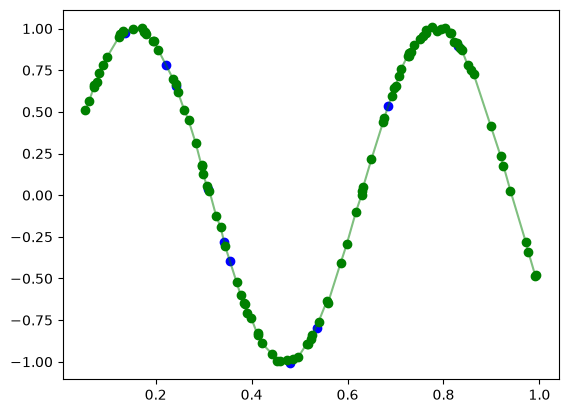

In [71]:
plt.scatter(x_train, y_train, label='Training Data', color='blue')
plt.scatter(x_test, y_test, label='Test Data', color='green')

plt.plot(x_test, y_test, alpha=0.5,label='Test Data', color='green')

In [72]:
from numpy.linalg import norm

def naive_laplace(x1, x2, L=10):
    return np.exp( -norm(x1 - x2) / L )

In [73]:
from numpy.linalg import solve
import time

# Implement K(X, x)
def kernel(x_test, x_train, L=10):
    n = len(x_test)
    m = len(x_train)

    K = np.zeros((n, m))
    for i in range(n):
        for j in range(m):
            K[i, j] = naive_laplace(x_test[i], x_train[j], L=L)
    return K

start = time.time()
kernel_matrix = kernel(x_train, x_train)

print(kernel_matrix.shape)
print(y_train.shape)

alpha = solve(kernel_matrix, np.array(y_train))
end = time.time()
print(f"Time taken to compute alpha: {end - start:.6f} seconds")

(10, 10)
(10, 1)
Time taken to compute alpha: 0.000483 seconds


In [74]:
start = time.time()

print(alpha.shape)
print(kernel(x_test, x_train).shape)

y_test_pred = kernel(x_test, x_train) @ alpha

end = time.time()
print(f"Time taken to compute y_test_pred: {end - start:.6f} seconds")

(10, 1)
(100, 10)
Time taken to compute y_test_pred: 0.004275 seconds


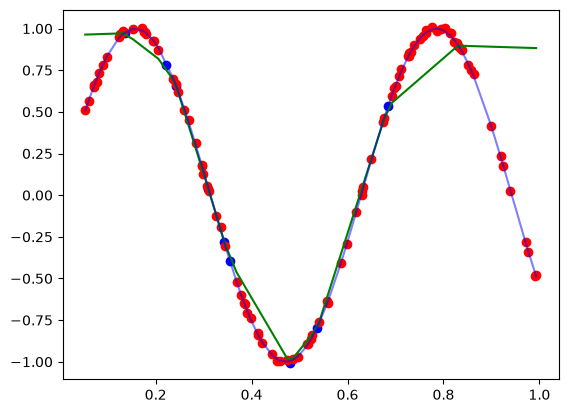

In [75]:
plt.scatter(x_train, y_train, label='Training Data', color='blue')
plt.scatter(x_test, y_test, label='Test Data', color='red')
plt.plot(x_test, y_test_pred, label='Predicted Function', color='green')
plt.plot(x_test, np.sin(10 * x_test), 'b-', alpha=.5, label='Test Data')

In [76]:
from sklearn.metrics import r2_score

test_r2 = r2_score(y_test, y_test_pred)
print("Test R2 Score: ", test_r2)  

Test R2 Score:  0.7842758794682335


# Vectorized Laplace

In [77]:
def euclidean_distance(X, Y, squared=True):
    # This is a vectorized (X-Y)^2 = X^2 - 2XY + Y^2

    x_dist = np.sum(X ** 2, axis=1).reshape(-1, 1)      # turn into column vector
    if X is Y:          # X is Y is slightly faster than X == Y
        y_dist = x_dist.reshape(1, -1)                  # I didn't turn it into column vector the first time 
                                                        # and that causes terrible prediction. It's a good practice 
                                                        # to always turn it into column vector.
    else:
        y_dist = np.sum(Y ** 2, axis=1).reshape(1, -1)    

    dist = X @ Y.T          # Inner product of rows of X and Y
    dist *= -2
    distance = x_dist + dist + y_dist

    if not squared:
        distance = np.where(distance < 0, 0, distance)  # prevent negative distances due to floating point errors
        distance = np.sqrt(distance)

    return distance

def laplacian_distancel(X, Y, bandwidth=10):
    assert bandwidth > 0, "bandwidth must be positive"
    euclidean_dist = euclidean_distance(X, Y, squared=False)
    euclidean_dist = np.where(euclidean_dist < 0, 0, euclidean_dist)
    bandwidth = 1 / bandwidth       # Note that "1." in the note is not necessary in python 3, 
                                    # but it is a good habit to use it to avoid integer division in Python 2.
    return np.exp(-bandwidth * euclidean_dist)

class LaplacianKernel:
    def __init__(self, bandwidth=10):
        self.bandwidth = bandwidth

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        self.alpha = solve(laplacian_distancel(X, X, self.bandwidth), y)

    def predict(self, X_test):
        K_test = laplacian_distancel(self.X_train, X_test, self.bandwidth)
        return K_test.T @ self.alpha


In [78]:
model = LaplacianKernel(bandwidth=10)

start = time.time()
model.fit(x_train, y_train)
end = time.time()
print(f"Time taken to fit the model: {end - start:.6f} seconds")

start = time.time()
model_predictions = model.predict(x_test)
end = time.time()
print(f"Time taken to predict: {end - start:.6f} seconds")

Time taken to fit the model: 0.000145 seconds
Time taken to predict: 0.000148 seconds


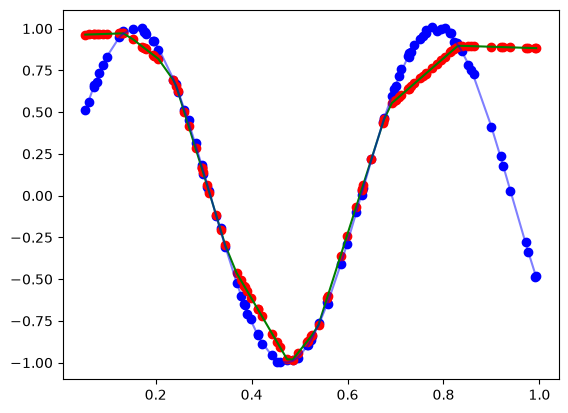

In [79]:
plt.scatter(x_test, y_test, label='Test Data', color='blue')
plt.scatter(x_test, model_predictions, label='Test Data', color='red')
plt.plot(x_test, model_predictions, label='Predicted Function', color='green')
plt.plot(x_test, np.sin(10 * x_test), 'b-', alpha=.5, label='Test Data')

In [80]:
model = LaplacianKernel(bandwidth=.001)

start = time.time()
model.fit(x_train, y_train)
end = time.time()
print(f"Time taken to fit the model: {end - start:.6f} seconds")

start = time.time()
model_predictions = model.predict(x_test)
end = time.time()
print(f"Time taken to predict: {end - start:.6f} seconds")

Time taken to fit the model: 0.000103 seconds
Time taken to predict: 0.000185 seconds


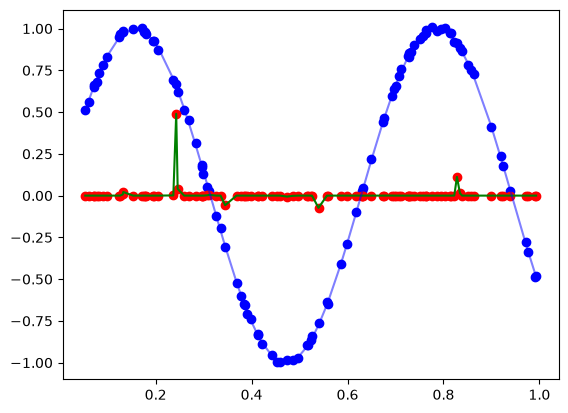

In [81]:
plt.scatter(x_test, y_test, label='Test Data', color='blue')
plt.scatter(x_test, model_predictions, label='Test Data', color='red')
plt.plot(x_test, model_predictions, label='Predicted Function', color='green')
plt.plot(x_test, np.sin(10 * x_test), 'b-', alpha=.5, label='Test Data')

In [82]:
model = LaplacianKernel(bandwidth=1000000000)

start = time.time()
model.fit(x_train, y_train)
end = time.time()
print(f"Time taken to fit the model: {end - start:.6f} seconds")

start = time.time()
model_predictions = model.predict(x_test)
end = time.time()
print(f"Time taken to predict: {end - start:.6f} seconds")

Time taken to fit the model: 0.000076 seconds
Time taken to predict: 0.000141 seconds


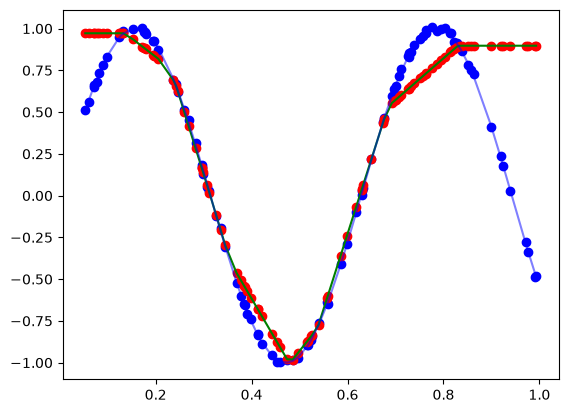

In [83]:
plt.scatter(x_test, y_test, label='Test Data', color='blue')
plt.scatter(x_test, model_predictions, label='Test Data', color='red')
plt.plot(x_test, model_predictions, label='Predicted Function', color='green')
plt.plot(x_test, np.sin(10 * x_test), 'b-', alpha=.5, label='Test Data')

# Regularized Laplacian Kernel

In [84]:
def sample_noisy_data(num_samples):
    e = np.random.normal(0, 0.1, size=(num_samples, 1))
    x = np.random.rand(num_samples, 1)
    y = np.sin(10 * x) + e

    return x, y

num_train, num_test = 10, 100

x_train, y_train = sample_noisy_data(num_train)
x_test, y_test = sample_noisy_data(num_test)

# zip -> sort -> unzip
x_test, y_test = zip(*sorted(zip(x_test, y_test)))
x_test, y_test = np.array(x_test), np.array(y_test)

print(x_train.shape, y_train.shape)

(10, 1) (10, 1)


In [85]:
class LaplacianKernel_Reg:
    def __init__(self, lambd=0.1, bandwidth=10):
        self.lambd = lambd
        self.bandwidth = bandwidth

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        self.alpha = solve((laplacian_distancel(X, X, self.bandwidth) + self.lambd * np.eye(X.shape[0])), y)

    def predict(self, X_test):
        K_test = laplacian_distancel(self.X_train, X_test, self.bandwidth)
        return K_test.T @ self.alpha

In [86]:
model = LaplacianKernel_Reg(bandwidth=10, lambd=1e-3)

start = time.time()
model.fit(x_train, y_train)
end = time.time()
print(f"Time taken to fit the model: {end - start:.6f} seconds")

start = time.time()
model_predictions = model.predict(x_test)
end = time.time()
print(f"Time taken to predict: {end - start:.6f} seconds")

Time taken to fit the model: 0.000107 seconds
Time taken to predict: 0.000327 seconds


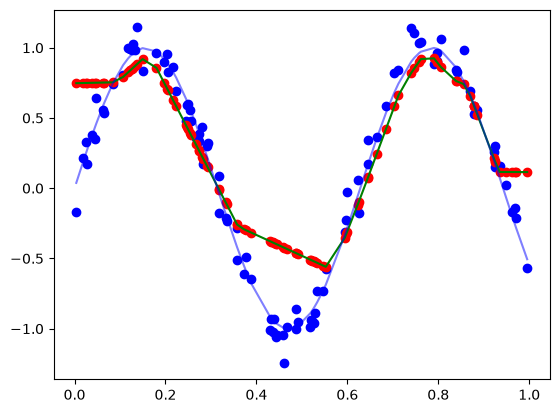

In [87]:
plt.scatter(x_test, y_test, label='Test Data', color='blue')
plt.scatter(x_test, model_predictions, label='Test Data', color='red')
plt.plot(x_test, model_predictions, label='Predicted Function', color='green')
plt.plot(x_test, np.sin(10 * x_test), 'b-', alpha=.5, label='Test Data')

In [88]:
model = LaplacianKernel_Reg(bandwidth=1e5, lambd=1e-2)

start = time.time()
model.fit(x_train, y_train)
end = time.time()
print(f"Time taken to fit the model: {end - start:.6f} seconds")

start = time.time()
model_predictions = model.predict(x_test)
end = time.time()
print(f"Time taken to predict: {end - start:.6f} seconds")

Time taken to fit the model: 0.000070 seconds
Time taken to predict: 0.000118 seconds


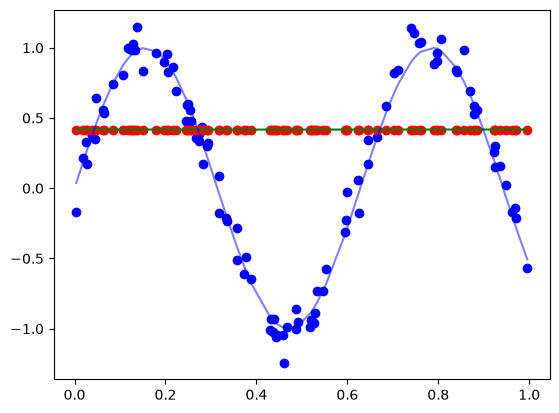

In [89]:
plt.scatter(x_test, y_test, label='Test Data', color='blue')
plt.scatter(x_test, model_predictions, label='Test Data', color='red')
plt.plot(x_test, model_predictions, label='Predicted Function', color='green')
plt.plot(x_test, np.sin(10 * x_test), 'b-', alpha=.5, label='Test Data')